<a href="https://colab.research.google.com/github/divyadharshiniug/24ADI006_24BAD023/blob/main/UNIT_3_ASSIGNMENT_24BAD023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Comparative Analysis of RNN, LSTM, and GRU for Sentiment Analysis
**Course:** 24ADI306 Deep Learning | **Assignment:** 3 | **CO3** | Bloom's Level: Apply & Analyze (K3-K4)

**Objective:** Implement and compare SimpleRNN, LSTM and GRU models for binary sentiment classification on the IMDB movie-review dataset, using Accuracy, Precision, Recall, F1-score and Training Time.

**Name:** `DIVYADHARSHINI U G`  **Roll No:** `24BAD023`

---
### Notebook roadmap
1. Setup and configuration
2. Dataset selection and loading
3. Exploratory data analysis
4. Text preprocessing (cleaning, tokenization, padding, split)
5. Model implementation (RNN / LSTM / GRU)
6. Training with timing
7. Training curves
8. Evaluation (Accuracy, Precision, Recall, F1, confusion matrix)
9. Comparison table and charts
10. Analysis and best model

> **Before you run:** go to `Runtime -> Change runtime type -> T4 GPU`, then `Runtime -> Run all`.

## 1. Setup and Configuration
All hyperparameters live in one place (`CONFIG`) so that the **three models are trained under identical conditions**. The only thing that changes between experiments is the recurrent layer type. This makes the comparison fair.

In [1]:
# Install the HuggingFace `datasets` library (used only to download raw IMDB text)
!pip install -q datasets

In [2]:
import os, re, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

print("TensorFlow version:", tf.__version__)
print("GPU available     :", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU available     : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# ---------------- Central configuration ----------------
CONFIG = {
    "seed"        : 42,
    "vocab_size"  : 10000,   # keep the 10,000 most frequent words
    "max_len"     : 200,     # every review is padded / truncated to 200 tokens
    "embed_dim"   : 128,     # size of the word-embedding vectors
    "hidden_units": 64,      # units in the recurrent layer
    "dropout"     : 0.5,     # Required by assignment rubric
    "batch_size"  : 64,
    "epochs"      : 10,      # upper limit; EarlyStopping may stop sooner
    "patience"    : 3,       # Required by assignment rubric
    "lr"          : 1e-3,
    "train_size"  : 0.70,
    "val_size"    : 0.15,
    "test_size"   : 0.15,
}

def set_seed(seed):
    # Fix all random sources for reproducibility
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

set_seed(CONFIG["seed"])
pd.DataFrame(CONFIG.items(), columns=["Hyperparameter", "Value"])

,Hyperparameter,Value
0,seed,42.000
1,vocab_size,10000.000
2,max_len,200.000
3,embed_dim,128.000
4,hidden_units,64.000
5,dropout,0.500
6,batch_size,64.000
7,epochs,10.000
8,patience,3.000
9,lr,0.001


## 2. Dataset Selection and Loading

**Dataset:** IMDB Large Movie Review Dataset (Maas et al., 2011) with **50,000 reviews** labelled *positive* (1) or *negative* (0).

**Why IMDB?**
- Perfectly **balanced** (25,000 positive / 25,000 negative), so Accuracy is a trustworthy metric.
- Reviews are **long and context-dependent**, which is exactly where the memory differences between RNN, LSTM and GRU become visible.
- It is a standard benchmark, so results are easy to compare with published work.
- It is distributed as **raw text**, so we get to perform genuine text pre-processing (cleaning, tokenization, padding).

We merge the official train and test portions (25K + 25K) and create our own stratified 70/15/15 split.

In [4]:
# Load the IMDB dataset directly from a reliable CSV mirror to bypass Hugging Face Hub URI errors
import pandas as pd

print("Downloading IMDB dataset...")
url = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"
df = pd.read_csv(url)

# Standardize column names and label encoding (positive -> 1, negative -> 0)
df = df.rename(columns={"review": "review", "sentiment": "sentiment"})
df["sentiment"] = df["sentiment"].map({"positive": 1, "negative": 0})

print("Total reviews:", len(df))
df.head()

Total reviews: 50000


,review,sentiment
0,One of the other reviewers has mentioned that ...,1
1,A wonderful little production. <br /><br />The...,1
2,I thought this was a wonderful way to spend ti...,1
3,Basically there's a family where a little boy ...,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",1


## 3. Exploratory Data Analysis
We check the class balance, missing values and the distribution of review lengths. The length distribution justifies our choice of `max_len`.

Missing values : 0
Duplicate rows : 418

Class distribution:
sentiment
Positive (1)    25000
Negative (0)    25000
Name: count, dtype: int64


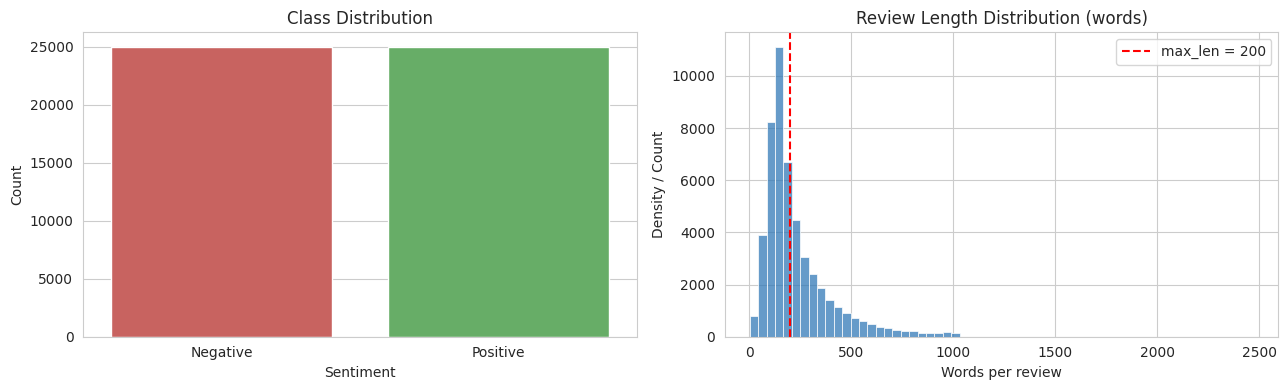


Min length      : 4 words
Max length      : 2470 words
Mean length     : 231.2 words
Median length   : 173 words
Reviews longer than max_len: 40.9%


In [5]:
print("Missing values :", df.isnull().sum().sum())
print("Duplicate rows :", df.duplicated().sum())
print("\nClass distribution:")
print(df["sentiment"].value_counts().rename({0: "Negative (0)", 1: "Positive (1)"}))

df["word_count"] = df["review"].str.split().str.len()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(x="sentiment", data=df, ax=ax[0], palette=["#d9534f", "#5cb85c"])
ax[0].set_xticklabels(["Negative", "Positive"])
ax[0].set_title("Class Distribution")
ax[0].set_xlabel("Sentiment")
ax[0].set_ylabel("Count")

sns.histplot(df["word_count"], bins=60, ax=ax[1], color="#337ab7")
ax[1].axvline(CONFIG["max_len"], color="red", linestyle="--",
              label=f"max_len = {CONFIG['max_len']}")
ax[1].set_title("Review Length Distribution (words)")
ax[1].set_xlabel("Words per review")
ax[1].set_ylabel("Density / Count")
ax[1].legend()
plt.tight_layout()
plt.savefig("review_length_distribution.png", dpi=150)
plt.show()

print(f"\nMin length      : {df['word_count'].min():.0f} words")
print(f"Max length      : {df['word_count'].max():.0f} words")
print(f"Mean length     : {df['word_count'].mean():.1f} words")
print(f"Median length   : {df['word_count'].median():.0f} words")
print(f"Reviews longer than max_len: {(df['word_count'] > CONFIG['max_len']).mean()*100:.1f}%")

**Observation:** The classes are perfectly balanced. Reviews vary widely in length; the median is around 175 words. We use `max_len = 200`, which fully covers roughly half of the reviews and keeps training time manageable. Longer reviews are truncated. This is a known limitation we will mention in the report.

## 4. Text Preprocessing

Pipeline: **Cleaning -> Train/Val/Test split -> Tokenization -> Padding**

**Cleaning steps**
1. Convert to lowercase
2. Remove HTML tags (IMDB text contains `<br />`)
3. Remove URLs
4. Remove punctuation, digits and special characters
5. Collapse extra whitespace

> **Design choice:** we deliberately do **not** remove stop-words. Words like *not*, *no*, *never* flip the sentiment ("not good"), and sequence models can use them.

In [6]:
def clean_text(text):
    text = text.lower()                                # 1. lowercase
    text = re.sub(r"<[^>]+>", " ", text)               # 2. HTML tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)      # 3. URLs
    text = re.sub(r"[^a-z\s]", " ", text)              # 4. punctuation / digits / symbols
    text = re.sub(r"\s+", " ", text).strip()           # 5. extra spaces
    return text

# ---- Before / after example ----
sample = df["review"].iloc[1]
print("BEFORE:\n", sample[:400], "...\n")
print("AFTER :\n", clean_text(sample)[:400], "...")

BEFORE:
 A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the voices down pat too! You can truly see the seamless editing guided by the referen ...

AFTER :
 a wonderful little production the filming technique is very unassuming very old time bbc fashion and gives a comforting and sometimes discomforting sense of realism to the entire piece the actors are extremely well chosen michael sheen not only has got all the polari but he has all the voices down pat too you can truly see the seamless editing guided by the references to williams diary entries not ...


In [7]:
df["clean_review"] = df["review"].apply(clean_text)
print("Cleaning complete.")
df[["clean_review", "sentiment"]].head()

Cleaning complete.


,clean_review,sentiment
0,one of the other reviewers has mentioned that ...,1
1,a wonderful little production the filming tech...,1
2,i thought this was a wonderful way to spend ti...,1
3,basically there s a family where a little boy ...,0
4,petter mattei s love in the time of money is a...,1


### 4.1 Stratified Train / Validation / Test Split (70 / 15 / 15)
We split **before** fitting the tokenizer so that no information from validation or test data leaks into the vocabulary.

In [8]:
X = df["clean_review"].values
y = df["sentiment"].values

# 70% train, 30% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=1 - CONFIG["train_size"],
    stratify=y, random_state=CONFIG["seed"])

# split temp equally -> 15% val, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5,
    stratify=y_temp, random_state=CONFIG["seed"])

print(f"Train : {len(X_train):>6}  (positive ratio {y_train.mean():.3f})")
print(f"Val   : {len(X_val):>6}  (positive ratio {y_val.mean():.3f})")
print(f"Test  : {len(X_test):>6}  (positive ratio {y_test.mean():.3f})")

Train :  34999  (positive ratio 0.500)
Val   :   7500  (positive ratio 0.500)
Test  :   7501  (positive ratio 0.500)


### 4.2 Tokenization and Padding
- `Tokenizer` builds a word -> integer index using the **training set only**, keeping the top 10,000 words. Everything else maps to the `<OOV>` token.
- `pad_sequences` makes every sequence exactly `max_len` long. We use **pre-padding** (zeros added at the start) so that the real words sit close to the end of the sequence, which is the point where the RNN produces its final output.

In [9]:
tokenizer = Tokenizer(num_words=CONFIG["vocab_size"], oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)                       # fit on TRAIN ONLY

def to_padded(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=CONFIG["max_len"],
                         padding="pre", truncating="post")

X_train_pad = to_padded(X_train)
X_val_pad   = to_padded(X_val)
X_test_pad  = to_padded(X_test)

print("Total unique words found in train :", len(tokenizer.word_index))
print("Vocabulary used by the model      :", CONFIG["vocab_size"])
print("X_train shape:", X_train_pad.shape)
print("X_val   shape:", X_val_pad.shape)
print("X_test  shape:", X_test_pad.shape)

print("\nExample (first 25 token ids of the last 50):")
print(X_train_pad[0][-50:][:25])
print("Text:", X_train[0][:120], "...")

Total unique words found in train : 85349
Vocabulary used by the model      : 10000
X_train shape: (34999, 200)
X_val   shape: (7500, 200)
X_test  shape: (7501, 200)

Example (first 25 token ids of the last 50):
[   5  493 3056    1    3    1 1929    9   18  972    5  918    1   10
   96   28  219  208    2 1148  542    9    2 3180 1212]
Text: a police officer robert forster in a crime ridden city has his wife attacked and young son killed after she dares to sta ...


## 5. Model Implementation

All three models share this architecture:

```
Input (200 token ids)
   -> Embedding (10000 x 128)
   -> [ SimpleRNN | LSTM | GRU ]  (64 units)
   -> Dropout (0.3)
   -> Dense (1, sigmoid)
```

A single function `build_model(rnn_type)` creates each one, so the **only difference is the recurrent layer**.

| Layer | Core idea |
|---|---|
| **SimpleRNN** | One hidden state updated every step. Suffers from vanishing gradients on long sequences. |
| **LSTM** | Adds a *cell state* plus **forget, input and output gates** to control what is remembered. |
| **GRU** | Simplified LSTM with **reset and update gates** and no separate cell state, so fewer parameters. |

In [10]:
def build_model(rnn_type, cfg=CONFIG):
    rnn_layers = {
        "SimpleRNN": layers.SimpleRNN,
        "LSTM"     : layers.LSTM,
        "GRU"      : layers.GRU,
    }
    set_seed(cfg["seed"])
    model = models.Sequential([
        layers.Input(shape=(cfg["max_len"],)),
        layers.Embedding(cfg["vocab_size"], cfg["embed_dim"]),
        rnn_layers[rnn_type](cfg["hidden_units"]),
        layers.Dropout(cfg["dropout"]),
        layers.Dense(1, activation="sigmoid"),
    ], name=rnn_type)
    model.compile(optimizer=tf.keras.optimizers.Adam(cfg["lr"]),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model

MODEL_NAMES = ["SimpleRNN", "LSTM", "GRU"]
for name in MODEL_NAMES:
    m = build_model(name)
    m.summary()
    print()

Model: "SimpleRNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,292,417 (4.93 MB)

 Trainable params: 1,292,417 (4.93 MB)

 Non-trainable params: 0 (0.00 B)

...

Model: "GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,317,313 (5.03 MB)

 Trainable params: 1,317,313 (5.03 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Training with Timing
For each model we:
- train with **EarlyStopping** on validation loss (restoring the best weights) to limit overfitting,
- measure **total training time** with `time.time()`,
- record the number of epochs actually run, so the time comparison is interpretable (a model that stops earlier naturally trains faster).

> This cell takes roughly **5-15 minutes** on a Colab T4 GPU. SimpleRNN is usually slowest per epoch on GPU because it has no fused cuDNN kernel.

In [11]:
results = {}      # will hold model, history, timing for every architecture

for name in MODEL_NAMES:
    print("=" * 70)
    print(f"Training {name}")
    print("=" * 70)

    model = build_model(name)

    early_stop = callbacks.EarlyStopping(
        monitor="val_loss", patience=CONFIG["patience"],
        restore_best_weights=True, verbose=1)

    start = time.time()
    history = model.fit(
        X_train_pad, y_train,
        validation_data=(X_val_pad, y_val),
        epochs=CONFIG["epochs"],
        batch_size=CONFIG["batch_size"],
        callbacks=[early_stop],
        verbose=1)
    train_time = time.time() - start

    epochs_run = len(history.history["loss"])
    results[name] = {
        "model"      : model,
        "history"    : history.history,
        "train_time" : train_time,
        "epochs_run" : epochs_run,
    }
    print(f"\n{name}: {train_time:.1f} s total | {epochs_run} epochs | "
          f"{train_time/epochs_run:.1f} s/epoch\n")

Training SimpleRNN
Epoch 1/10
547/547 ━━━━━━━━━━━━━━━━━━━━ 16s 23ms/step - accuracy: 0.6058 - loss: 0.6566 - val_accuracy: 0.6168 - val_loss: 0.6440
Epoch 2/10
547/547 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.7362 - loss: 0.5333 - val_accuracy: 0.7928 - val_loss: 0.4804
Epoch 3/10
547/547 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.8158 - loss: 0.4093 - val_accuracy: 0.6257 - val_loss: 0.6981
Epoch 4/10
547/547 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.9174 - loss: 0.2165 - val_accuracy: 0.6916 - val_loss: 0.7712
Epoch 5/10
547/547 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.9648 - loss: 0.1002 - val_accuracy: 0.6976 - val_loss: 0.9550
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.

SimpleRNN: 53.9 s total | 5 epochs | 10.8 s/epoch

Training LSTM
Epoch 1/10
547/547 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.7847 - loss: 0.4611 - val_accuracy: 0.8540 - val_loss: 0.3675
Epoch 2/10
547/547 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step 

## 7. Training Curves
Curves reveal learning speed, stability and overfitting. A widening gap between training and validation lines signals overfitting.

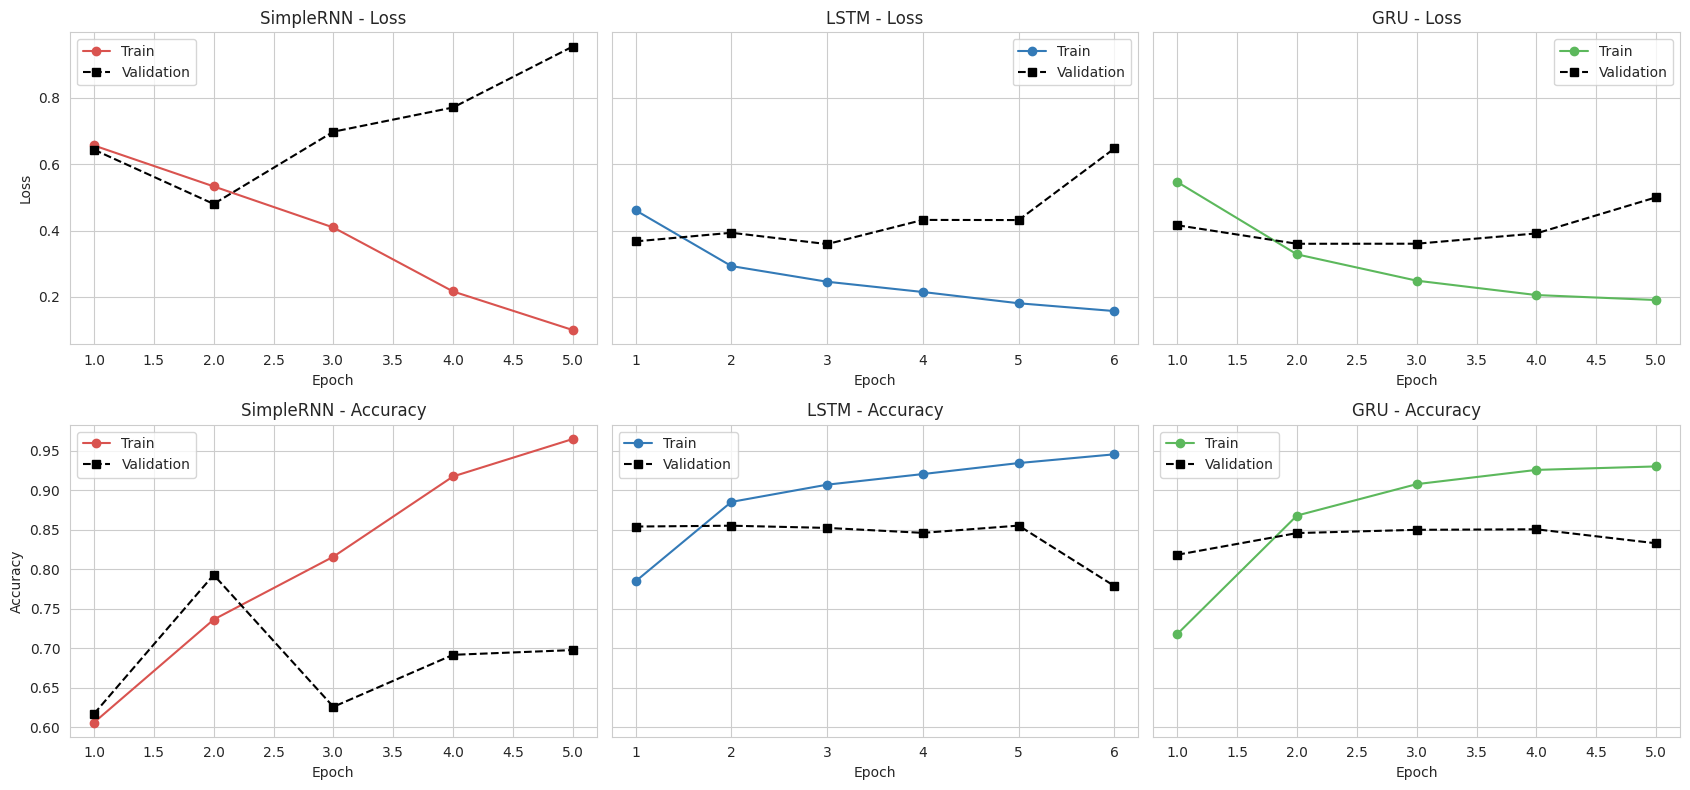

In [12]:
colors = {"SimpleRNN": "#d9534f", "LSTM": "#337ab7", "GRU": "#5cb85c"}
fig, ax = plt.subplots(2, 3, figsize=(17, 8), sharey="row")

for i, name in enumerate(MODEL_NAMES):
    h = results[name]["history"]
    ep = range(1, len(h["loss"]) + 1)

    ax[0, i].plot(ep, h["loss"], "o-", label="Train", color=colors[name])
    ax[0, i].plot(ep, h["val_loss"], "s--", label="Validation", color="black")
    ax[0, i].set_title(f"{name} - Loss")
    ax[0, i].set_xlabel("Epoch"); ax[0, i].legend()

    ax[1, i].plot(ep, h["accuracy"], "o-", label="Train", color=colors[name])
    ax[1, i].plot(ep, h["val_accuracy"], "s--", label="Validation", color="black")
    ax[1, i].set_title(f"{name} - Accuracy")
    ax[1, i].set_xlabel("Epoch"); ax[1, i].legend()

ax[0, 0].set_ylabel("Loss"); ax[1, 0].set_ylabel("Accuracy")
plt.tight_layout()
plt.show()

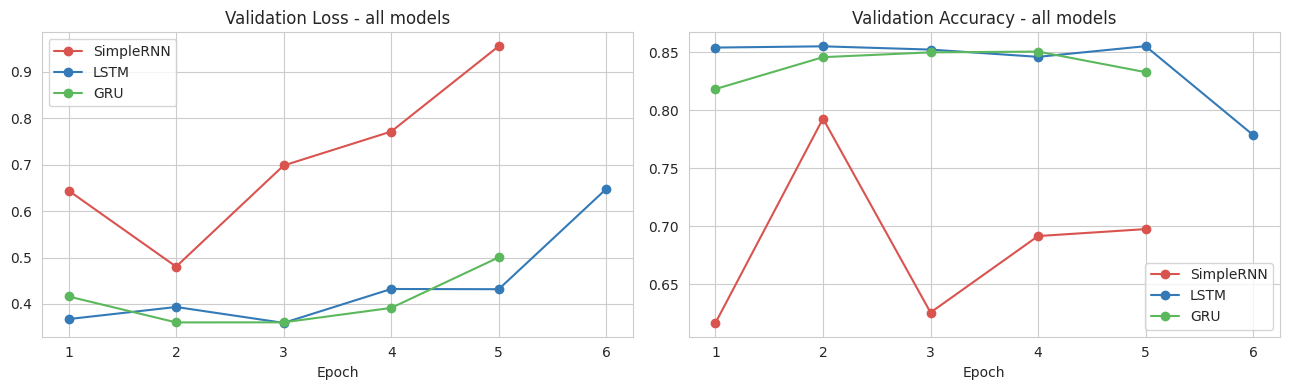

In [13]:
# Overlay of validation curves for a direct comparison
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name in MODEL_NAMES:
    h = results[name]["history"]
    ep = range(1, len(h["val_loss"]) + 1)
    ax[0].plot(ep, h["val_loss"], "o-", label=name, color=colors[name])
    ax[1].plot(ep, h["val_accuracy"], "o-", label=name, color=colors[name])
ax[0].set_title("Validation Loss - all models");     ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].set_title("Validation Accuracy - all models"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout()
plt.show()

## 8. Evaluation on the Held-out Test Set
Metrics are computed on the **test set**, which was never used for training or early stopping.

- **Accuracy**: overall fraction correct
- **Precision**: of the reviews predicted positive, how many really are
- **Recall**: of the truly positive reviews, how many were found
- **F1-score**: harmonic mean of Precision and Recall

In [14]:
rows = []

for name in MODEL_NAMES:
    model = results[name]["model"]

    # Prediction (also timed, to report inference speed)
    t0 = time.time()
    y_prob = model.predict(X_test_pad, batch_size=256, verbose=0).ravel()
    infer_time = time.time() - t0
    y_pred = (y_prob >= 0.5).astype(int)

    results[name]["y_pred"] = y_pred
    results[name]["y_prob"] = y_prob

    rows.append({
        "Model"               : name,
        "Accuracy"            : accuracy_score(y_test, y_pred),
        "Precision"           : precision_score(y_test, y_pred),
        "Recall"              : recall_score(y_test, y_pred),
        "F1-score"            : f1_score(y_test, y_pred),
        "Training Time (s)"   : results[name]["train_time"],
        "Epochs Run"          : results[name]["epochs_run"],
        "Time / Epoch (s)"    : results[name]["train_time"] / results[name]["epochs_run"],
        "Inference Time (s)"  : infer_time,
        "Trainable Params"    : model.count_params(),
    })

    print(f"\n{'='*60}\n{name} - Classification Report (Test set)\n{'='*60}")
    print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"], digits=4))


SimpleRNN - Classification Report (Test set)
              precision    recall  f1-score   support

    Negative     0.8003    0.7971    0.7987      3751
    Positive     0.7979    0.8011    0.7995      3750

    accuracy                         0.7991      7501
   macro avg     0.7991    0.7991    0.7991      7501
weighted avg     0.7991    0.7991    0.7991      7501


LSTM - Classification Report (Test set)
              precision    recall  f1-score   support

    Negative     0.8509    0.8867    0.8684      3751
    Positive     0.8817    0.8445    0.8627      3750

    accuracy                         0.8656      7501
   macro avg     0.8663    0.8656    0.8656      7501
weighted avg     0.8663    0.8656    0.8656      7501


GRU - Classification Report (Test set)
              precision    recall  f1-score   support

    Negative     0.8875    0.8283    0.8569      3751
    Positive     0.8390    0.8949    0.8661      3750

    accuracy                         0.8616      7501
 

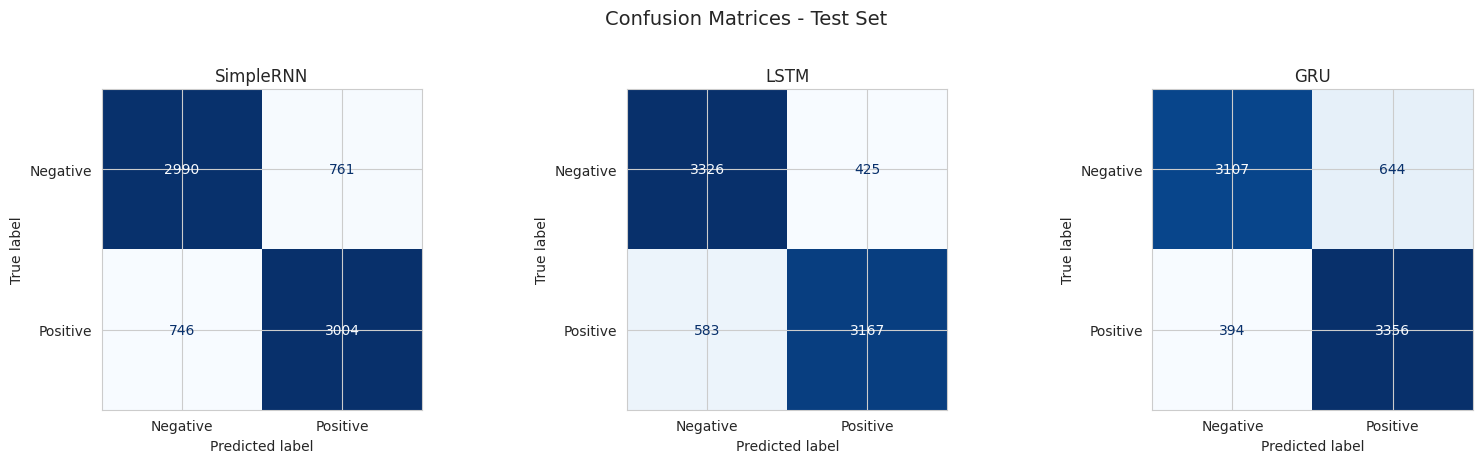

In [15]:
# Confusion matrices
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for i, name in enumerate(MODEL_NAMES):
    cm = confusion_matrix(y_test, results[name]["y_pred"])
    ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(
        ax=ax[i], cmap="Blues", colorbar=False, values_format="d")
    ax[i].set_title(f"{name}")
plt.suptitle("Confusion Matrices - Test Set", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

## 9. Comparison Table and Charts

In [16]:
comparison = pd.DataFrame(rows).set_index("Model")

# Round for presentation
display_df = comparison.copy()
for c in ["Accuracy", "Precision", "Recall", "F1-score"]:
    display_df[c] = display_df[c].round(4)
for c in ["Training Time (s)", "Time / Epoch (s)", "Inference Time (s)"]:
    display_df[c] = display_df[c].round(2)

comparison.round(4).to_csv("comparison_table.csv")
print("Saved -> comparison_table.csv\n")

# Highlight the best value in each metric column
(display_df.style
    .highlight_max(subset=["Accuracy", "Precision", "Recall", "F1-score"], color="#c6efce")
    .highlight_min(subset=["Training Time (s)", "Time / Epoch (s)",
                           "Inference Time (s)", "Trainable Params"], color="#c6efce")
    .format(precision=4))

Saved -> comparison_table.csv



,Accuracy,Precision,Recall,F1-score,Training Time (s),Epochs Run,Time / Epoch (s),Inference Time (s),Trainable Params
Model,,,,,,,,,
SimpleRNN,0.7991,0.7979,0.8011,0.7995,53.9200,5,10.7800,1.1200,1292417
LSTM,0.8656,0.8817,0.8445,0.8627,48.5700,6,8.0900,0.4500,1329473
GRU,0.8616,0.8390,0.8949,0.8661,40.8900,5,8.1800,0.4100,1317313


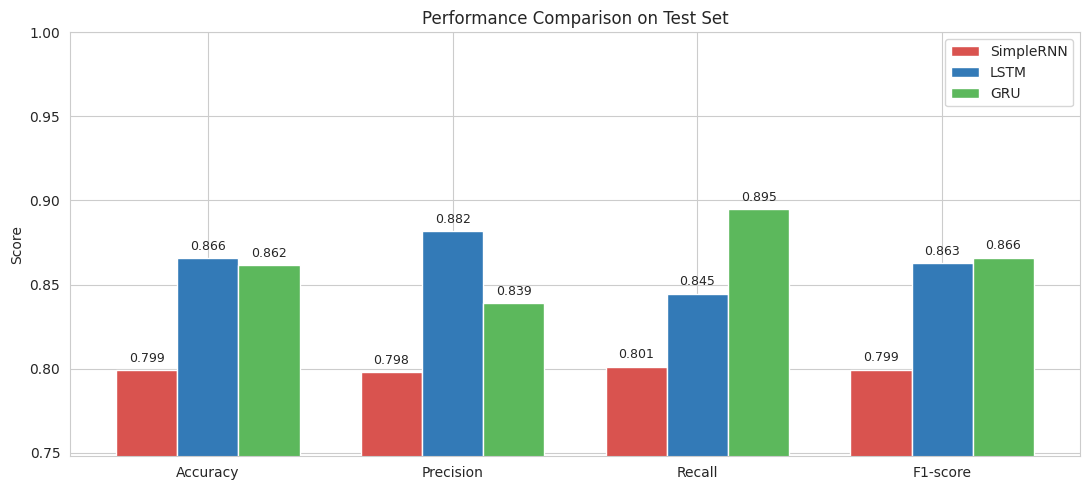

In [17]:
# Grouped bar chart of the four quality metrics
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(11, 5))
for i, name in enumerate(MODEL_NAMES):
    vals = comparison.loc[name, metrics].values
    bars = ax.bar(x + (i - 1) * width, vals, width, label=name, color=colors[name])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.005, f"{v:.3f}",
                ha="center", fontsize=9)

lo = max(0, comparison[metrics].values.min() - 0.05)
ax.set_ylim(lo, 1.0)
ax.set_xticks(x); ax.set_xticklabels(metrics)
ax.set_ylabel("Score"); ax.set_title("Performance Comparison on Test Set")
ax.legend()
plt.tight_layout()
plt.savefig("metrics_comparison.png", dpi=200)
plt.show()

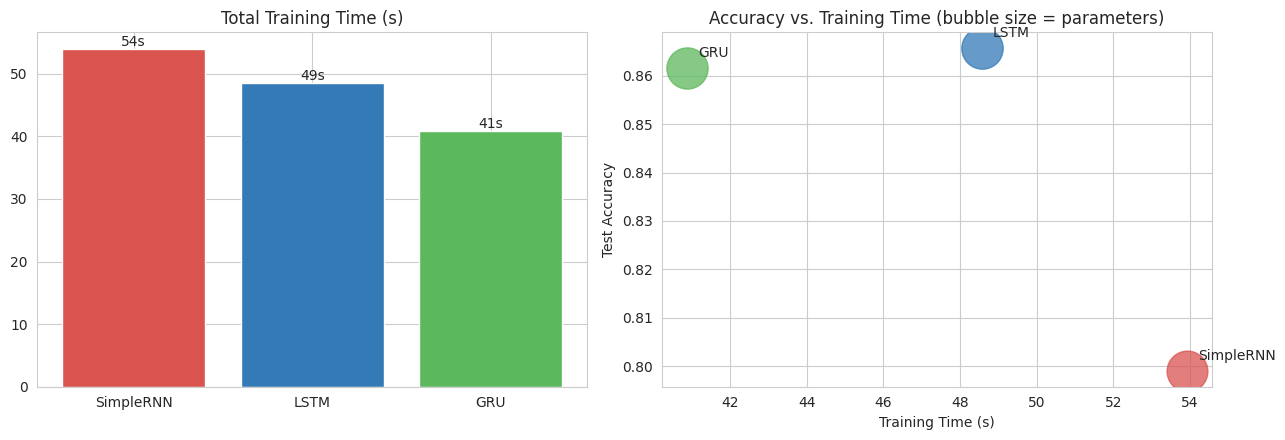

In [18]:
# Training time vs. accuracy trade-off
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].bar(MODEL_NAMES, comparison["Training Time (s)"],
          color=[colors[m] for m in MODEL_NAMES])
ax[0].set_title("Total Training Time (s)")
for i, v in enumerate(comparison["Training Time (s)"]):
    ax[0].text(i, v, f"{v:.0f}s", ha="center", va="bottom")

for name in MODEL_NAMES:
    ax[1].scatter(comparison.loc[name, "Training Time (s)"],
                  comparison.loc[name, "Accuracy"],
                  s=comparison.loc[name, "Trainable Params"] / 1500,
                  color=colors[name], alpha=0.75, label=name)
    ax[1].annotate(name, (comparison.loc[name, "Training Time (s)"],
                          comparison.loc[name, "Accuracy"]),
                   textcoords="offset points", xytext=(8, 8))
ax[1].set_xlabel("Training Time (s)"); ax[1].set_ylabel("Test Accuracy")
ax[1].set_title("Accuracy vs. Training Time (bubble size = parameters)")
plt.tight_layout()
plt.savefig("time_vs_accuracy.png", dpi=200)
plt.show()

## 10. Analysis and Best Model
The cell below automatically identifies the best model by each criterion and by an overall ranking.

In [19]:
best_f1   = comparison["F1-score"].idxmax()
best_acc  = comparison["Accuracy"].idxmax()
fastest   = comparison["Training Time (s)"].idxmin()
smallest  = comparison["Trainable Params"].idxmin()

print("Best Accuracy      :", best_acc,  f"({comparison.loc[best_acc, 'Accuracy']:.4f})")
print("Best F1-score      :", best_f1,   f"({comparison.loc[best_f1, 'F1-score']:.4f})")
print("Fastest training   :", fastest,   f"({comparison.loc[fastest, 'Training Time (s)']:.1f} s)")
print("Fewest parameters  :", smallest,  f"({int(comparison.loc[smallest, 'Trainable Params']):,})")

# Overall rank = average of ranks across quality + speed criteria
rank_df = pd.DataFrame({
    "Accuracy rank" : comparison["Accuracy"].rank(ascending=False),
    "F1 rank"       : comparison["F1-score"].rank(ascending=False),
    "Time rank"     : comparison["Training Time (s)"].rank(ascending=True),
})
rank_df["Average rank"] = rank_df.mean(axis=1)
print("\nOverall ranking (lower is better):")
print(rank_df.sort_values("Average rank"))

# Generalization gap (train acc - val acc at the best epoch)
print("\nOverfitting check (final train acc vs. val acc):")
for name in MODEL_NAMES:
    h = results[name]["history"]
    gap = h["accuracy"][-1] - h["val_accuracy"][-1]
    print(f"  {name:<10} train={h['accuracy'][-1]:.4f}  val={h['val_accuracy'][-1]:.4f}  gap={gap:+.4f}")

Best Accuracy      : LSTM (0.8656)
Best F1-score      : GRU (0.8661)
Fastest training   : GRU (40.9 s)
Fewest parameters  : SimpleRNN (1,292,417)

Overall ranking (lower is better):
           Accuracy rank  F1 rank  Time rank  Average rank
Model                                                     
GRU                  2.0      1.0        1.0      1.333333
LSTM                 1.0      2.0        2.0      1.666667
SimpleRNN            3.0      3.0        3.0      3.000000

Overfitting check (final train acc vs. val acc):
  SimpleRNN  train=0.9648  val=0.6976  gap=+0.2672
  LSTM       train=0.9455  val=0.7787  gap=+0.1668
  GRU        train=0.9301  val=0.8328  gap=+0.0973


### Written Analysis (fill in after seeing YOUR results)

Replace the placeholders using the numbers printed above. Do not copy this text blindly; base every statement on your own output.

**1. Best performing model:** `[MODEL]` achieved the highest test F1-score of `[VALUE]` and accuracy of `[VALUE]`.

**2. RNN behaviour:** SimpleRNN scored `[VALUE]`. Its curves `[were unstable / learned slowly / plateaued near 50-70%]`, consistent with the **vanishing-gradient problem** over 200 time-steps.

**3. LSTM vs GRU:** The gap between them was `[VALUE]`. LSTM has `[N]` parameters versus `[N]` for GRU. GRU trained `[faster / slower]` by `[X]` seconds.

**4. Accuracy vs. cost trade-off:** `[Discuss whether the extra accuracy of the best model justifies its training time and parameters.]`

**5. Overfitting:** `[Which model showed the largest train-validation gap? Was early stopping triggered?]`

**6. Precision vs Recall:** `[Did any model favour one class? Refer to the confusion matrices.]`

**7. Limitations:**
- Reviews truncated to 200 tokens (information lost in long reviews)
- Embeddings trained from scratch (no GloVe / Word2Vec)
- Single training run with one seed, so small differences may be noise
- Early stopping makes training time depend on the number of epochs run

**8. Future work:** Bidirectional layers, attention mechanisms, pre-trained embeddings (GloVe), multiple seeds with mean +/- std, and Transformer models such as BERT.

In [20]:
# Download deliverables (works in Google Colab)
try:
    from google.colab import files
    for f in ["comparison_table.csv", "metrics_comparison.png", "time_vs_accuracy.png"]:
        files.download(f)
except ImportError:
    print("Not running in Colab - files are saved in the working directory.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>